# Identify eastward-propagating ensemble members

Follow `Identify_direction.ipynb`: choose the NoRad wavenumber with the largest
linear growth rate, measure the late-time phase change of complex `J1`, and keep
members with positive phase speed. When multiple experiments are enabled, keep
the same number of members in each (the first qualifying indices, as in the reference).

Here the ensemble axis is first and the wavenumber axis is last. Direction must
be measured from `State.h5`, before daily averaging or taking the real part.

## Load packages

In [1]:
import h5py
import numpy as np

from typing import cast
from pathlib import Path

from matplotlib import pyplot as plt

style_path = Path("/home/b11209013/Kuang-python/v0.1.0_Analysis/scientific.mplstyle")

plt.style.use(style_path)

## Configure runs

In [2]:
data_path: Path = Path("/work/b11209013/Kuang-python/v0.1.0/two-way")
EXPS: list[str] = ["NoRad", "Rad"]
FILES: list[str] = ["2026-10-28-07-25-19-242016551-4092283", "2026-10-28-08-37-05-996147668-3800833"]

# Process only the first entry for now. Use EXPS[:] after updating the Rad path.
active_exps = EXPS
run_paths = {exp: data_path / exp / run for exp, run in zip(EXPS, FILES)}
phase_samples: int = 20
output_root: Path = data_path / "Eastward"

## Select the most unstable NoRad wavenumber

In [3]:
with h5py.File(run_paths["NoRad"] / "EigenAnalysis.h5", "r") as f:
    k = cast(h5py.Dataset, f["k"])[:]
    growthrate = cast(h5py.Dataset, f["GrowthRates"])[:]  # (eigenmode, wavenumber)

max_growthrate = np.max(growthrate, axis=0)
norad_most_unstable = int(np.argmax(max_growthrate))
selected_k = float(k[norad_most_unstable])
if not np.isfinite(selected_k) or selected_k == 0:
    raise ValueError("Propagation direction requires a finite, nonzero wavenumber.")


def matching_mode(wavenumbers, target):
    """Find the same wavenumber even when a run has a different index order."""
    matches = np.flatnonzero(np.isclose(wavenumbers, target, rtol=1e-10, atol=0))
    if matches.size != 1:
        raise ValueError(f"Expected one match for k={target}; found {matches.size}.")
    return int(matches[0])


print(f"NoRad most unstable wavenumber: index={norad_most_unstable}, k={selected_k:.6g}")

NoRad most unstable wavenumber: index=15, k=5.08634


## Identify direction from the last 20 saved states

With the model convention $\mathrm{Re}[J_1(t)e^{ikx/L}]$, eastward propagation
has decreasing phase for positive $k$. For each member, compute
$\Delta\phi_j=\arg[J_1(t_{j+1})J_1(t_j)^*]$ and
$c=-L\sum_j\Delta\phi_j/(k\Delta t)$, converting days to seconds for m/s.

Twenty snapshots contain **19 intervals**. Use their actual elapsed time rather
than the reference's `20 * 0.25` denominator. This changes the speed magnitude,
not the direction selection. Adjacent phase changes must be smaller than $\pi$
in magnitude to avoid temporal aliasing. Zero or nonfinite coefficients have
undefined phase and are excluded.

In [4]:
def phase_speed_from_j1(j1, times, wavenumber, reference_length_m):
    """Return one phase speed (m/s) per member; input shape is (ensemble, time)."""
    j1 = np.asarray(j1)
    times = np.asarray(times)
    if j1.ndim != 2 or times.ndim != 1 or j1.shape[1] != times.size or times.size < 2:
        raise ValueError("J1 must have shape (ensemble, time) with at least two times.")
    if not np.all(np.isfinite(times)) or np.any(np.diff(times) <= 0):
        raise ValueError("Saved times must be finite and strictly increasing.")
    if not np.isfinite(wavenumber) or wavenumber == 0:
        raise ValueError("Wavenumber must be finite and nonzero.")
    if not np.isfinite(reference_length_m) or reference_length_m <= 0:
        raise ValueError("Reference length must be positive and finite.")
    valid = np.all(np.isfinite(j1) & (np.abs(j1) > 0), axis=1)
    speeds = np.full(j1.shape[0], np.nan)
    # Unit phasors avoid overflow in the product as the unstable amplitudes grow.
    phasors = j1[valid] / np.abs(j1[valid])
    dphi = np.angle(phasors[:, 1:] * np.conj(phasors[:, :-1]))
    elapsed_seconds = (times[-1] - times[0]) * 86400.0
    speeds[valid] = -dphi.sum(axis=1) * reference_length_m / (wavenumber * elapsed_seconds)
    return speeds


phase_speeds = {}
eastward_candidates = {}
mode_indices = {}
state_times = {}
phase_windows = {}
reference_lengths = {}
for exp in active_exps:
    with h5py.File(run_paths[exp] / "Metadata.h5", "r") as meta, \
            h5py.File(run_paths[exp] / "State.h5", "r") as state:
        if not meta.attrs.get("complete", False) or not state.attrs.get("complete", False):
            raise ValueError(f"{exp}: simulation files are incomplete.")
        times = cast(h5py.Dataset, meta["time"])[:]
        mode = matching_mode(meta["k"][:], selected_k)
        j1 = cast(h5py.Dataset, state["J1"])
        if j1.shape != (int(meta["nEnsemble"][()]), times.size, meta["k"].size):
            raise ValueError(f"{exp}: unexpected J1 dimensions {j1.shape}.")
        if not 2 <= phase_samples <= times.size:
            raise ValueError(f"phase_samples must be between 2 and {times.size}.")
        reference_lengths[exp] = float(meta.attrs["reference_length_m"])
        if not np.isclose(reference_lengths[exp], reference_lengths[active_exps[0]]):
            raise ValueError("Experiments must use the same reference length for a common k.")
        phase_windows[exp] = times[-phase_samples:]
        phase_speeds[exp] = phase_speed_from_j1(
            j1[:, -phase_samples:, mode], phase_windows[exp], selected_k,
            reference_lengths[exp],
        )
        mode_indices[exp] = mode
        state_times[exp] = times
    eastward_candidates[exp] = np.flatnonzero(phase_speeds[exp] > 0)

# Preserve ascending source indices and balance counts only across enabled runs.
number_valid = min(indices.size for indices in eastward_candidates.values())
eastward_indices = {exp: indices[:number_valid] for exp, indices in eastward_candidates.items()}
for exp in active_exps:
    print(f"{exp}: {eastward_candidates[exp].size}/{phase_speeds[exp].size} eastward; "
          f"retaining {eastward_indices[exp].size} members")
    print("Selected original ensemble indices:", eastward_indices[exp])

NoRad: 104/200 eastward; retaining 90 members
Selected original ensemble indices: [  3   4   6   7  11  12  13  14  16  18  21  22  23  24  29  30  33  35
  40  41  42  43  44  46  47  48  49  50  51  52  54  56  57  58  60  64
  73  75  78  85  88  89  90  91  92  93  94  96  98  99 101 104 105 106
 107 110 111 112 114 115 116 118 119 121 123 124 126 127 131 132 134 138
 140 141 143 144 149 150 151 152 153 154 156 158 159 160 167 169 171 172]
Rad: 90/200 eastward; retaining 90 members
Selected original ensemble indices: [  0   2   3   6   8  13  14  15  18  19  20  22  23  26  30  32  33  36
  37  43  48  50  52  53  56  57  61  64  73  74  76  80  81  82  84  85
  86  87  89  92  95  98 100 101 104 111 112 114 116 117 118 121 122 125
 127 129 131 132 133 134 138 139 141 142 144 145 147 149 150 152 153 154
 155 158 160 162 164 166 171 172 175 178 179 181 187 189 191 192 193 197]


## Inspect phase speeds

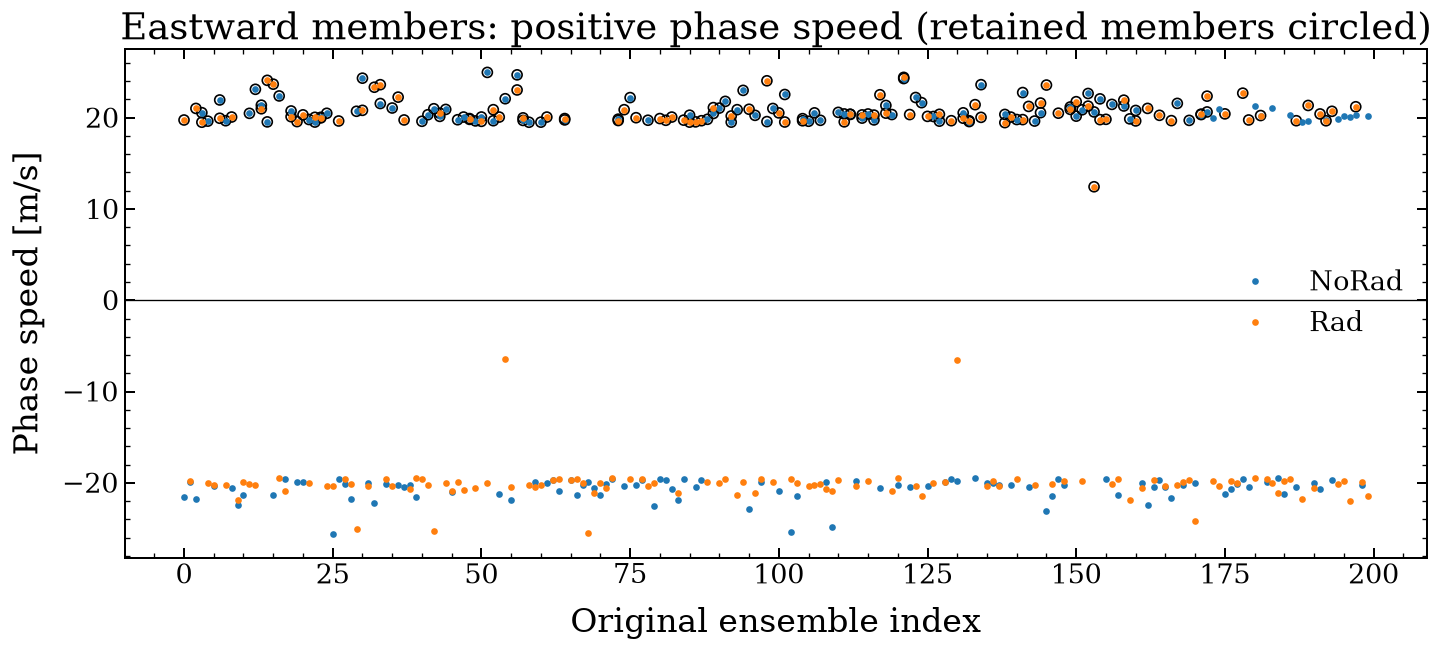

In [5]:
fig, ax = plt.subplots()
for exp in active_exps:
    ax.plot(np.arange(phase_speeds[exp].size), phase_speeds[exp], ".", label=exp)
    indices = eastward_indices[exp]
    ax.scatter(indices, phase_speeds[exp][indices], facecolors="none", edgecolors="k")
ax.axhline(0, color="k", linewidth=0.8)
ax.set(xlabel="Original ensemble index", ylabel="Phase speed [m/s]",
       title="Eastward members: positive phase speed (retained members circled)")
ax.legend()
plt.show()

## Inspect one selected member in physical space

Overlay the final two daily heating fields, as in the original exploratory plot.
Read only those two snapshots of one retained member. This preview is skipped
when a run has no `GalerkinState.h5` or no selected eastward members.

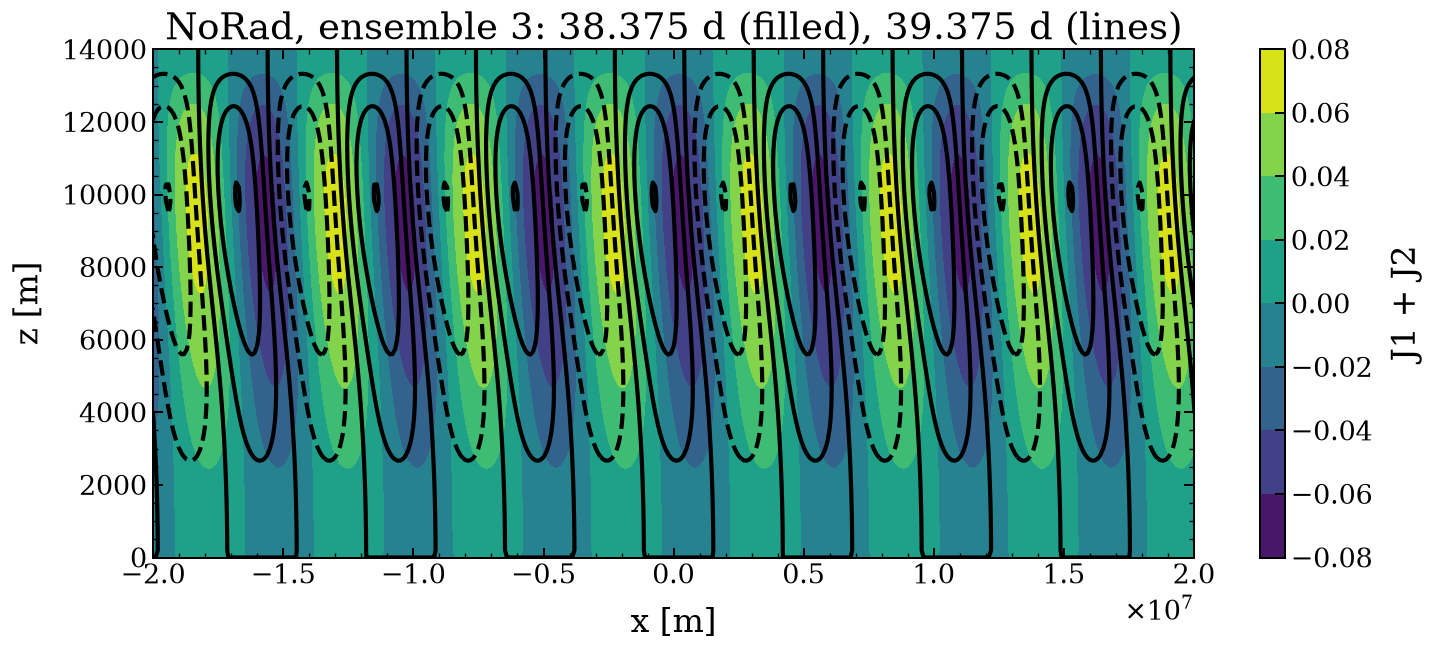

In [6]:
preview_exp = active_exps[0]
selected_member = 0  # Position in eastward_indices, not the original ensemble index.
preview_path = run_paths[preview_exp] / "GalerkinState.h5"
if eastward_indices[preview_exp].size == 0:
    print(f"{preview_exp}: no eastward members to preview.")
elif not preview_path.exists():
    print(f"{preview_exp}: GalerkinState.h5 is not available yet.")
else:
    ensemble = int(eastward_indices[preview_exp][selected_member])
    with h5py.File(preview_path, "r") as f:
        mode = matching_mode(f["k"][:], selected_k)
        x, z, t = (f[name][:] for name in ("x", "z", "time"))
        heating = f["J1"][ensemble, -2:, :, :, mode] + f["J2"][ensemble, -2:, :, :, mode]
    if t.size < 2:
        raise ValueError("The preview needs at least two reconstructed times.")
    fig, ax = plt.subplots()
    ctf = ax.contourf(x, z, heating[0].T)
    ax.contour(x, z, heating[1].T, colors="k")
    fig.colorbar(ctf, ax=ax, label="J1 + J2")
    ax.set(xlabel="x [m]", ylabel="z [m]",
           title=f"{preview_exp}, ensemble {ensemble}: {t[-2]:g} d (filled), {t[-1]:g} d (lines)")
    plt.show()

## Export the selected states

Write `State.h5`, `FourierState.h5`, and `GalerkinState.h5` under
`output_root / experiment / run_id`. Each export removes the wavenumber axis
and preserves the other axis order: `(ensemble, time)`, `(ensemble, day, x)`,
or `(ensemble, day, x, z)`. Original ensemble indices, phase speeds, coordinates,
and selection-window metadata accompany the fields. State times are the full
saved times; reconstructed fields retain their own daily times.

The export streams one time slice of the selected members at a time. Missing
reconstructed files are reported and skipped, so direction identification and
State export can be used before reconstruction finishes. Rerunning the final
cell replaces the exports in this output directory.

In [7]:
def export_eastward(exp, filename):
    source_path = run_paths[exp] / filename
    if not source_path.exists():
        if filename == "State.h5":
            raise FileNotFoundError(source_path)
        print(f"Skipped {exp}/{filename}: reconstruction is not available yet.")
        return
    destination = output_root / exp / run_paths[exp].name / filename
    if destination.resolve() == source_path.resolve():
        raise ValueError("Export destination must differ from the source file.")
    indices = eastward_indices[exp]
    axes = {
        "State.h5": "ensemble, time",
        "FourierState.h5": "ensemble, day, x",
        "GalerkinState.h5": "ensemble, day, x, z",
    }[filename]
    with h5py.File(source_path, "r") as source:
        if not source.attrs.get("complete", False):
            raise ValueError(f"{source_path}: source file is incomplete.")
        mode = (mode_indices[exp] if filename == "State.h5"
                else matching_mode(source["k"][:], selected_k))
        destination.parent.mkdir(parents=True, exist_ok=True)
        with h5py.File(destination, "w") as out:
            out.attrs.update(dict(source.attrs))
            out.attrs.update(
                complete=False, experiment=exp, propagation_direction="eastward",
                source_directory=str(run_paths[exp].resolve()),
                most_unstable_mode=mode, norad_most_unstable_mode=norad_most_unstable,
                wavenumber=selected_k, reference_length_m=reference_lengths[exp],
                phase_samples=phase_samples, phase_start_day=phase_windows[exp][0],
                phase_end_day=phase_windows[exp][-1],
            )
            out.create_dataset("k", data=selected_k)
            if filename == "State.h5":
                out.create_dataset("time", data=state_times[exp])
            else:
                for coordinate in ("time", "x", "z"):
                    if coordinate in source:
                        source.copy(coordinate, out)
            out.create_dataset("ensemble_indices", data=indices).attrs["index_base"] = 0
            out.create_dataset("phase_speed", data=phase_speeds[exp][indices]).attrs["units"] = "m s^-1"
            for name, field in source.items():
                if name in ("k", "time", "x", "z"):
                    continue
                dataset = out.create_dataset(
                    name, shape=(indices.size, *field.shape[1:-1]), dtype=field.dtype,
                    compression="gzip", compression_opts=4, shuffle=True,
                )
                dataset.attrs.update(dict(field.attrs))
                dataset.attrs["axes"] = axes
                dataset.attrs["axis_order"] = axes
                if indices.size:
                    for it in range(field.shape[1]):
                        dataset[:, it, ...] = field[indices, it, ..., mode]
            out.attrs["complete"] = True
    print(f"Saved {exp}: {indices.size} eastward members to {destination}")

In [8]:
for exp in active_exps:
    for filename in ("State.h5", "FourierState.h5", "GalerkinState.h5"):
        export_eastward(exp, filename)

Saved NoRad: 90 eastward members to /work/b11209013/Kuang-python/v0.1.0/two-way/Eastward/NoRad/2026-10-28-07-25-19-242016551-4092283/State.h5
Saved NoRad: 90 eastward members to /work/b11209013/Kuang-python/v0.1.0/two-way/Eastward/NoRad/2026-10-28-07-25-19-242016551-4092283/FourierState.h5
Saved NoRad: 90 eastward members to /work/b11209013/Kuang-python/v0.1.0/two-way/Eastward/NoRad/2026-10-28-07-25-19-242016551-4092283/GalerkinState.h5
Saved Rad: 90 eastward members to /work/b11209013/Kuang-python/v0.1.0/two-way/Eastward/Rad/2026-10-28-08-37-05-996147668-3800833/State.h5
Saved Rad: 90 eastward members to /work/b11209013/Kuang-python/v0.1.0/two-way/Eastward/Rad/2026-10-28-08-37-05-996147668-3800833/FourierState.h5
Saved Rad: 90 eastward members to /work/b11209013/Kuang-python/v0.1.0/two-way/Eastward/Rad/2026-10-28-08-37-05-996147668-3800833/GalerkinState.h5
